# Buyer GPT, version 1 (B1): what we did, step by step

**Sell Anything, notebook 4.** In the game the player draws a cat and sells it at a market. A few AI buyers take
turns asking the seller (the player) questions, and after every answer each of them says one line with a reason
and moves their offer up, down or not at all. At the end each buyer pictures the cat at their own home.

B1 is the first version in which **every buyer decides everything themselves**: what to ask, how to react, how much
to offer and what to picture all come from one GPT. The game engine only decides whose turn it is to ask. This
notebook goes through what we did in order, what each step measured, and where B1 still falls short.
Every number is computed from the files when the notebook runs.

| Step | What |
|---|---|
| 1 | Collect 100 official cat sales (48 generated by Qwen and corrected line by line, 52 written from scratch) |
| 2 | Check every line with program rules |
| 3 | Turn each sale into training examples: "what one buyer knows at this moment → what they do next" |
| 4 | Fine-tune a pre-trained 71M-parameter model |
| 5 | Score it on 10 held-out sales |
| 6 | Find the problems and their causes |


In [1]:
import json
import re
import statistics
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

ML = Path.cwd().parent
sys.path.insert(0, str(ML))                     # so the notebook can import ml/sellanything_ml
from sellanything_ml.buyers import sales_sft as S
from sellanything_ml.buyers import stories
from sellanything_ml.llm.tokenizer import TOKENIZER_DIR, Tokenizer

tok = Tokenizer(TOKENIZER_DIR / "sp8192.model")

## 1. Data: 100 official cat sales

Every sale has the same shape: ten buyers, each with a card (who they are, what they care about, a budget), open
with a greeting and an offer. Then up to ten rounds: one buyer asks, the seller answers, and **every buyer still
bidding** says one line and moves their offer. At the end the buyers still bidding each picture a scene (three
drawable things and one line), and the cat goes to the best offer.

B1 uses two sources:

In [2]:
sales = {p.name: [json.loads(line) for line in open(p)] for p in S.SOURCES_B1}
for name, rows in sales.items():
    events = Counter(e["kind"] for s in rows for e in s["events"])
    reviewed = [e for s in rows for e in s["events"] if e.get("edited_by")]
    changed = [e for e in reviewed if e.get("original") is not None and e["original"] != e["says"]]
    print(f"{name}: {len(rows)} sales, {events['ask']} questions, {events['react']} reactions, "
          f"{events['imagine']} scenes, {len(reviewed)} lines reviewed, {len(changed)} of them rewritten")

buyer_sales_v9_official.jsonl: 48 sales, 451 questions, 4258 reactions, 427 scenes, 4736 lines reviewed, 4532 of them rewritten
sales.jsonl: 52 sales, 471 questions, 4120 reactions, 424 scenes, 0 lines reviewed, 0 of them rewritten


The 48 v9 sales were generated by Qwen2.5-32B, but Qwen's lines often gave no reason ("that's exactly what I
want"), claimed FIV can pass to dogs, or reacted to things nobody had said. So every line was read: 4,736 lines
carry an `edited_by` mark and 4,532 of them were actually rewritten (the old line is kept in `original`). The other
52 sales were written from scratch, so there is nothing to compare them with. Here is what a sale looks like:

In [3]:
sale = sales["sales.jsonl"][0]
for e in sale["events"][:4] + [e for e in sale["events"] if e["kind"] in ("ask", "answer")][:2] + \
        [e for e in sale["events"] if e["kind"] == "react"][:3] + [e for e in sale["events"] if e["kind"] == "imagine"][:1]:
    print(e["kind"].ljust(8), {k: v for k, v in e.items() if k not in ("kind",)})

open     {'name': 'Chloe', 'offer': 65, 'says': "Hi! My kids have been drawing cats on everything for months, so I promised them we'd finally look at one."}
open     {'name': 'Andre', 'offer': 150, 'says': "Good afternoon. I keep a small collection of pedigree cats and I'm always looking for a well-bred Bengal."}
open     {'name': 'Mei', 'offer': 100, 'says': "Oh, she's gorgeous in the photo. I redid my whole living room in gold and cream and she'd fit right in."}
open     {'name': 'Jonah', 'offer': 70, 'says': "Hey there. My old girl Daisy is fourteen and I think she'd like some company in the afternoons."}
ask      {'round': 1, 'name': 'Andre', 'offer': 150, 'says': 'Is she a purebred Bengal, and do you have registration papers or a pedigree for her?'}
answer   {'round': 1, 'to': 'Andre', 'q': 'Is she a purebred Bengal, and do you have registration papers or a pedigree for her?', 'says': 'yeah shes a bengal, 2 yrs old. no papers tho, i got her from a friend whose cat had a litter so 

A reaction has three parts: a **sign** (+ raise, - lower or walk away, 0 keep), **what the buyer says** (it
has to name what the seller just said and what that means for the buyer's own life) and the **new offer**.

## 2. Program rules

Every line has to pass `stories.reaction_problem` and `stories.imagine_problem`. The rules were added one at a
time, each after reading sales and finding a kind of mistake. A few test lines:

In [4]:
card = {"budget": 80}
tests = [
    ({"sign": "+", "offer": 70, "says": "Calm and lazy suits my small flat. Up to $70."}, "good line"),
    ({"sign": "+", "offer": 60, "says": "Nice. Up to $60."}, "+ but no move"),
    ({"sign": "0", "offer": 60, "says": "That's exactly what I want. $60."}, "empty reason"),
    ({"sign": "0", "offer": 60, "says": "I like her. $60."}, "ignores answer"),
    ({"sign": "-", "offer": 50, "says": "FIV worries me \u2014 down to $50."}, "dash"),
]
for row, label in tests:
    print(f"{label:16} -> {stories.reaction_problem(row, card, 60, 'Ben', 'She is calm and lazy.')}")

good line        -> None
+ but no move    -> sign + does not match the offer going from $60 to $60
empty reason     -> "exactly what i want" gives no reason; say what was just said and what it means for your own life
ignores answer   -> an unchanged offer must name what the seller just said
dash             -> the line uses a dash


The first line passes (`None`); the others are stopped: a sign that does not match the offer, an empty reason,
an unchanged offer that never mentions what the seller just said, and a dash. These rules only catch mistakes of
form. Whether a reason makes sense, or whether a buyer counts the same fact twice, still has to be read by a person.

## 3. Training examples: each buyer sees only what they know

`sales_sft.py` cuts a sale into many examples. Each one is what **one** buyer can see at that moment → what they do
next. B1 uses prompt format 4: the card shows a budget, the last two rounds are kept in full and older rounds keep
only their questions. **A buyer never sees the other buyers' reactions.**

In [5]:
ex = S.examples(sales["sales.jsonl"][5], prompt_format=4)
print(Counter(e["task"] for e in ex))
react = [e for e in ex if e["task"] == "react"][25]
print(react["prompt"].replace("<|end|>", "<|end|>\n"))
print("target ->", react["target"])

Counter({'react': 91, 'open': 10, 'ask': 10, 'imagine': 9})
<|item|>cat<|end|>
<|persona|>Ines, who is a nurse working night shifts | cares about: independent, quiet in the day, easy care | budget $80 | offer now $55<|end|>
<|log|>Your opening ($55): Hi. I'm a night nurse, so I sleep in the daytime.
Hana asked: You called her rare. What makes her rare, and is she a pedigree?
Seller: Calicos are special, every coat is one of a kind! No pedigree papers, but honestly you won't find another like her.
You ($55 -> $55): No papers is fine. $55.
Felix asked: She lived with a dog? Was it a big one, and did they actually get along or just put up with each other?
Seller: They were best buddies! A big lab, they napped together all the time.
You ($55 -> $55): Napping together sounds sweet. $55.
You asked: I'm out all night. What is she like at night?
Seller: She's full of life at night! Playful, chatty, a real night owl.<|end|>
<|react|>
target -> + | A night owl who plays while I'm at work and sle

The prompt holds the card (with the budget and the current offer), the buyer's own opening, the questions asked
earlier, the last two rounds in full and then this round's question and answer. The target is "sign | what they
say | new offer". `<|react|>` tells the model which job it is doing (the other three are `<|open|>`, `<|ask|>` and
`<|imagine|>`).

In [6]:
b1 = {split: [json.loads(line) for line in open(ML / "data/processed/buyers_b1" / f"{split}.jsonl")]
      for split in ("train", "val")}
for split, rows in b1.items():
    print(split, len({r["seed"] for r in rows}), "sales", dict(Counter(r["task"] for r in rows)))
lengths = [len(tok.encode(r["prompt"] + r["target"])) for r in b1["train"]]
print("tokens: median", statistics.median(lengths), " longest", max(lengths), " over 512:", sum(x > 512 for x in lengths))

train 90 sales {'open': 900, 'ask': 824, 'react': 7470, 'imagine': 762}
val 10 sales {'open': 100, 'ask': 98, 'react': 908, 'imagine': 89}


tokens: median 327.0  longest 725  over 512: 1987


90 sales for training and 10 for validation, split by a hash of each sale's seed, so adding sales later never
moves one across. Every example fits in 768 tokens, but pre-training only used 512-token pieces, so the positions
past 512 are learned for the first time during fine-tuning.

## 4. Training

Starting from `pretrain_large` (pre-trained on 1.28B tokens, 71M parameters): 3 epochs, lr 3e-4, batch 8, loss on
the target tokens only, about 60 minutes on the Mac. Two false starts first: at batch 16 the Mac ran out of memory
and started swapping (the slowdown watchdog stopped it at step 200), and with an MPS memory cap the batch did not
fit at all. Batch 8 was stable.

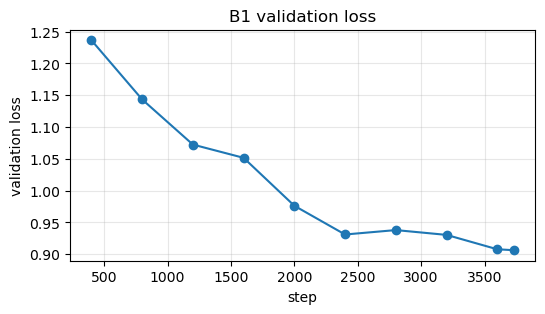

first evaluation 1.236 -> last 0.906


In [7]:
metrics = [json.loads(line) for line in open(ML / "runs/sft_b1/metrics.jsonl")]
steps = [m["step"] for m in metrics]
vals = [m["val_loss"] for m in metrics]
plt.figure(figsize=(6, 3))
plt.plot(steps, vals, marker="o")
plt.xlabel("step"); plt.ylabel("validation loss"); plt.title("B1 validation loss")
plt.grid(alpha=0.3); plt.show()
print("first evaluation", round(vals[0], 3), "-> last", round(vals[-1], 3))

The validation loss keeps falling and is still going down slowly at the end, so three epochs did not use up
what the data can teach. But the training loss ends around 0.41, far below the validation 0.906: the model is
**memorising** the training sales, and step 6 shows the evidence.

## 5. Scoring on the 10 held-out sales

`tools/eval_buyer_b1.py` lets the model write every validation example the way the game samples (temperature 0.7)
and checks each line with **the same program rules the training sales passed**. The training sales score 100% on
every check, so 100% is the ceiling.

In [8]:
before = json.load(open(ML / "runs/sft_b1/eval_before_sft.json"))["tasks"]
after = json.load(open(ML / "runs/sft_b1/eval_v2_no_budget.json"))["tasks"]
rows = [("open: readable", "open", "readable"), ("ask: readable", "ask", "readable"),
        ("ask: new in meaning", "ask", "new_in_meaning"), ("react: readable", "react", "readable"),
        ("react: passes the rules", "react", "rules_ok"), ("react: same direction as the sale", "react", "same_direction"),
        ("react: amount said = offer", "react", "said_equals_offer"), ("imagine: passes the rules", "imagine", "rules_ok")]
print(f"{'':36}{'before SFT':>11}{'B1':>8}")
for label, task, key in rows:
    b = before.get(task, {}).get(key, "-")
    print(f"{label:36}{b if b == '-' else f'{b:.1%}':>11}{after[task][key]:>8.1%}")
print("most common reaction problems:", list(after["react"]["problems"].items())[:2])

                                     before SFT      B1
open: readable                             0.0%  100.0%
ask: readable                            100.0%  100.0%
ask: new in meaning                           -   89.8%
react: readable                            0.0%   99.6%
react: passes the rules                       -   90.2%
react: same direction as the sale             -   78.8%
react: amount said = offer                    -   99.9%
imagine: passes the rules                  0.0%   70.8%
most common reaction problems: [('an unchanged offer must name what the seller just said', 85), ('sign - does not match the offer going from $N to $N', 1)]


Before fine-tuning the model cannot even write the format (0% readable openings and reactions). After it, the
format is almost always right and 90% of the reactions pass the rules. But only about 79% move the offer the same
way as the buyer in the real sale, only about 71% of scenes pass, and most failed reactions break the same rule: the
offer stays the same without naming what the seller just said.

## 6. Problems and their causes

Playing one sale in the game (notebook 5 shows it line by line) showed these problems; for each one we went back to
the data for the cause:

In [9]:
train_targets = [r["target"] for r in b1["train"]]
for phrase in ["Having lived with a dog", "overdue check-up", "to protect her bare skin", "by the picture frame of my old girl"]:
    hits = sum(phrase.lower() in t.lower() for t in train_targets)
    print(f"{phrase!r}: {hits} training targets")

'Having lived with a dog': 14 training targets
'overdue check-up': 2 training targets
'to protect her bare skin': 1 training targets
'by the picture frame of my old girl': 14 training targets


**1. Stitching phrases instead of reading the answer.** The model joins phrases that are common in the training
sales: after "she has never lived with dogs" it still says "Having lived with a dog…", and some scene lines are
copied word for word. With 90 sales and 71M parameters, memorising is easy.

In [10]:
at_budget = [r for r in b1["train"] if r["task"] == "react"
             and re.search(r"offer now \$(\d+)", r["prompt"])[1] == re.search(r"budget \$(\d+)", r["prompt"])[1]]
print("reactions that start at the budget:", len(at_budget), " of which raise:", sum(r["target"].startswith("+") for r in at_budget))

reactions that start at the budget: 220  of which raise: 0


**2. Going over its own budget.** None of the 220 reactions that start at the budget raises the offer, so the
pattern is in the data, but learning it means comparing two numbers in the prompt, which the model has not learned
from 90 sales. Decision for version 2: **buyers have no budget**; their moves only have to be reasonable (format 5).

In [11]:
s = S.Story("Ann")
s.opening = "Your opening ($60): Hi."
for k in range(1, 5):
    s.asked("Bo", f"Question {k}?")
    s.rounds[-1].append(f"Seller: Answer {k}.")
print(s.text())

Your opening ($60): Hi.
Asked earlier: Question 1? / Question 2?
Bo asked: Question 3?
Seller: Answer 3.
Bo asked: Question 4?
Seller: Answer 4.


**3. Only the last two rounds.** By round 4 the answers of rounds 1 and 2 are gone from the prompt (only the
questions remain), so the model asks again or makes a fact up. The people who wrote the sales saw the whole sale;
the model sees part of it, which teaches it to guess. Keeping every round would exceed the model's 1,024-token
limit, so the plan is to let each buyer **write a short note** of every answer.

**4. Data size.** TinyStories needed about 2.12 million short stories (about 500M tokens) before small models wrote
coherent text; our 100 sales hold about 270K tokens. Version 2 starts with the data: more high-quality sales,
written under stricter quality checks.

## B1 version info

The data, weights and commands needed to reproduce B1 are listed in `docs/model-versions.md`.

In [12]:
import hashlib
for f in ["data/processed/buyers_b1/train.jsonl", "data/processed/buyers_b1/val.jsonl", "runs/sft_b1/best.pt"]:
    print(hashlib.sha256((ML / f).read_bytes()).hexdigest()[:16], f)

a6d9ec1fb5dec112 data/processed/buyers_b1/train.jsonl
42fa95f461a50442 data/processed/buyers_b1/val.jsonl


6c4517b868ccb2b9 runs/sft_b1/best.pt


The hashes match the B1 entry in `docs/model-versions.md`, so this notebook read the same data and model that
were trained.